***Week 11 Jupyter Notebook — Assignment Instructions***

Each week, apply the concepts to the Integrated Capstone Project dataset in a Jupyter Notebook, analyze the data and draw interesting conclusions. For this week, include **DBSCAN, hierarchical agglomerative clustering, linkage methods and dendrograms**. Complete the homework by 11:59pm ET on Sunday. In Week 12, compile findings into Milestone Two.

**Yellowdig:** showcase at least one high-quality source, link/cite it and explain its quality; investigate and respectfully respond to peers' sources. A draft initial post is included below. Peer replies require the actual peer posts and are not fabricated.

The referenced **Mod C Milestone Two Guidelines and Rubric** link/content was not supplied, so rubric-specific coverage cannot be verified. This notebook addresses the supplied concepts; course submission is separate.

# Week 11: Density and hierarchical clustering

Calvin Baker · DX799 Integrated Capstone · Three independent datasets

## tl;dr

- **Loan Default (n=2,000):** DBSCAN finds **4 clusters with 17.0% noise** at eps=0.512 and min_samples=10. Selected HAC uses **Ward, k=2**, full-sample silhouette **0.406**, and closely agrees with k-means (**ARI 0.976**).
- **LendingClub (n=2,000):** **none of the tested DBSCAN candidates meets the stated multi-cluster, size and coverage rules**. The displayed lowest-noise fit is a single cluster with 0.75% noise and has no defined silhouette. Selected HAC uses **Ward, k=3**, silhouette **0.138**; agreement with k-means is only **ARI 0.270**, indicating sensitivity to algorithm choice.
- **Bank (n=39):** DBSCAN finds **5 clusters with 38.5% noise**. Selected HAC uses **average linkage, k=2**, silhouette **0.488**, with the same partition as k-means (**ARI 1.000**). The small repeated-account sample limits interpretation.
- Four linkage methods and their dendrograms reveal how nearest-pair chaining, farthest-pair, average-distance and Ward merges differ. DBSCAN silhouette excludes noise, so it must be read with coverage and cannot be directly ranked against full-sample HAC/k-means scores.

Outcome fractions are descriptive profiles after clustering. No result establishes predictive accuracy, a causal effect or a validated business segment.

## Context & Methods

**Question:** What borrower/account profiles emerge without fitting an outcome label, and how much do the groups depend on geometry and algorithm choices?

### Key Assumptions

- Analyze the three CSVs independently. Reconstruct Week 9's 12,000-row loan samples, then take a seed-42 uniform subsample of 2,000 per loan dataset; use all eligible bank records. Week 10 and Week 11 use identical numeric feature rows. This changes the analysis population from the full supervised experiments.
- Loan_Default uses loan amount, income, credit score and term. LendingClub uses log1p loan amount, log1p income, FICO midpoint, debt-to-income ratio, revolving utilization and open-account count. Bank uses age and historical tenure in years. Categorical features are omitted to keep the distance weighting explicit; groups describe only this numeric view.
- Keep the prior resolved-2015, 36-month LendingClub cohort for continuity. Conditioning on resolution limits the population; these clusters do not describe all originations. Loan_Default status timing remains undocumented. Bank eligibility/reference date stays **September 26, 2026** for comparability, not the execution date.
- Median imputation and scaling fit this exploratory sample. There is no held-out predictive performance claim. Outcomes (recorded status, charge-off, checking type) never enter distances or parameter selection, but the LendingClub cohort itself depends on resolution status.
- Standard scaling is the primary geometry. It gives features equal variance, not equal business relevance, and remains sensitive to extremes. No silent winsorization. Repeated or correlated features can change effective weighting. Bank rows may repeat accounts and are not established independent customers.
- At least max(3, ceil(1% of sample size)) records per cluster is an explicit exploratory size rule. Candidate ranges are bounded choices, not exhaustive searches or discovered truths. Do not use demographic profiles or cluster labels as credit decisions.

## Data

Original inputs are local `DATA/Loan_Default.csv`, `DATA/accepted_2007_to_2018Q4.csv` and `DATA/bank_customers.csv`. No external data are added. Audits below reconcile source/cohort/sample counts and print a feature fingerprint for matching the weeks. SSNs are not loaded; identifiers and exact dates are not displayed or used as numeric features.

### 1. Set up a reproducible environment

Use the repository’s `requirements-notebooks.txt`. Run from the repository or its parent. Each notebook is self-contained; no prior fitted objects or cached data are required.

In [1]:
from pathlib import Path
import platform
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
import sklearn
from IPython.display import display, Markdown
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score, pairwise_distances
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from scipy.cluster.hierarchy import linkage, dendrogram, cut_tree, cophenet
from scipy.spatial.distance import pdist
from threadpoolctl import threadpool_limits

SEED = 42
SAMPLE_SIZE = 12_000  # Reconstruct the prior week's cohorts before clustering subsampling.
CLUSTER_SAMPLE = 2_000  # Same rows for both weeks; bounds pairwise-memory/time costs.
thread_limit = threadpool_limits(limits=1)
pd.set_option('display.max_columns', 12)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
plt.rcParams.update({'figure.figsize': (10, 4.5), 'figure.dpi': 110,
    'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': .15, 'axes.axisbelow': True})
DATA_DIR = next((p for p in [Path.cwd()/'DATA',
    Path.cwd()/'Data-Science-Capstone-DX799'/'DATA'] if p.is_dir()), None)
if DATA_DIR is None:
    raise FileNotFoundError('Run from the repository or its parent; original DATA files are required.')
display(pd.Series({'Python': platform.python_version(), 'NumPy': np.__version__,
    'pandas': pd.__version__, 'scikit-learn': sklearn.__version__,
    'SciPy': scipy.__version__, 'seed': SEED}, name='Execution environment'))
results = []

Python          3.13.5
NumPy            2.4.1
pandas           3.0.0
scikit-learn     1.8.0
SciPy           1.17.0
seed                42
Name: Execution environment, dtype: object

### 2. Define shared analysis helpers

In [2]:
def cluster_stats(labels):
    labels = np.asarray(labels)
    counts = pd.Series(labels[labels != -1]).value_counts()
    return {'clusters': len(counts), 'noise fraction': float(np.mean(labels == -1)),
            'smallest cluster': int(counts.min()) if len(counts) else 0,
            'largest share': float(counts.max()/len(labels)) if len(counts) else 0.0}

def safe_silhouette(data, labels):
    # DBSCAN noise is excluded explicitly; a single remaining cluster is undefined.
    mask = np.asarray(labels) != -1
    lab = np.asarray(labels)[mask]
    if not 2 <= len(np.unique(lab)) < len(lab):
        return np.nan
    return silhouette_score(data[mask], lab, metric='euclidean')

def profile(labels, title):
    # Original analysis units; log variables remain log1p units, not dollars.
    table = X.assign(cluster=labels, **{'profile outcome': y.to_numpy()}).groupby('cluster').agg(
        n=('profile outcome', 'size'), **{'outcome fraction': ('profile outcome', 'mean')})
    table = table.join(X.assign(cluster=labels).groupby('cluster').median().add_prefix('median '))
    assert table['n'].sum() == len(X)
    display(Markdown(f'**{title}.** Outcome fraction = {outcome_label}; descriptive only.'))
    display(table)
    return table

def scatter_clusters(coords, labels, ax, title):
    markers = ['o', 's', '^', 'D', 'v', 'P', 'X', '<', '>']
    for i, label in enumerate(sorted(np.unique(labels))):
        mask = labels == label
        noise = label == -1
        ax.scatter(coords[mask, 0], coords[mask, 1], s=20 if len(coords)>100 else 45,
            alpha=.65, marker='x' if noise else markers[i % len(markers)],
            color='#666666' if noise else plt.get_cmap('tab10')(i % 10),
            label='Noise' if noise else f'C{label} (n={mask.sum()})')
    ax.set(title=title, xlabel='PC1 (standardized-feature projection)', ylabel='PC2')
    ax.legend(fontsize=8, loc='best', ncol=2)

## Results: method guide

**DBSCAN** grows connected dense neighborhoods. Core records have at least min_samples records (including self) within eps; border records adjoin a core without meeting that count; other records receive noise label −1. We try three min_samples settings and four quantiles of the corresponding neighbor-distance curve. Select the largest assigned-only silhouette among fits with at least two clusters, the minimum cluster size and at most 40% noise. If none qualify, retain that failure and display a lowest-noise illustrative fit. These explicit rules balance separation with coverage; a global density radius can struggle with varying densities.

**HAC** repeatedly merges clusters. Compare single, complete, average and Ward linkage on identical standard-scaled Euclidean distances and exact-k cuts from 2–8. Select the largest full-sample silhouette satisfying the size rule. The dendrogram shows nested merges, and the cophenetic correlation measures how faithfully merge heights represent original pairwise distances. No predictive generalization is inferred.

References: [DBSCAN](https://scikit-learn.org/1.8/modules/generated/sklearn.cluster.DBSCAN.html), [SciPy linkage](https://docs.scipy.org/doc/scipy/reference/generated/scipy.cluster.hierarchy.linkage.html), [clustering guide](https://scikit-learn.org/stable/modules/clustering.html).

## A. Loan_Default.csv

### A1. Reconstruct the source cohort

In [3]:
dataset_name = 'Loan_Default.csv'
outcome_label = 'recorded Status 1'
source_frame = pd.read_csv(DATA_DIR / dataset_name)
assert source_frame['ID'].notna().all() and source_frame['ID'].is_unique
assert source_frame['Status'].notna().all() and set(source_frame['Status'].unique()) == {0,1}
assert not source_frame.duplicated().any()
# Uniform sampling is independent of outcome. Preserve original indices for audits.
frame = source_frame.sample(n=min(SAMPLE_SIZE, len(source_frame)), random_state=SEED).copy()
numeric = ['loan_amount', 'income', 'Credit_Score', 'term']
categorical = ['loan_type', 'loan_purpose', 'occupancy_type']
X = frame[numeric + categorical].copy()
for name in categorical:
    X[name] = X[name].astype(object).where(X[name].notna(), np.nan)
y = frame['Status'].astype(int)
groups = None
display(pd.Series({'source rows':len(source_frame), 'valid target rows':len(source_frame),
    'uniform modeling sample':len(frame), 'not sampled':len(source_frame)-len(frame)}, name='Source reconciliation'))

source rows                148670
valid target rows          148670
uniform modeling sample     12000
not sampled                136670
Name: Source reconciliation, dtype: int64

### A2. Audit the shared clustering sample

In [4]:
# Use numeric features only: categorical one-hot block weights would add a separate geometry choice.
X = X[numeric].replace([np.inf, -np.inf], np.nan).reset_index(drop=True)
y = y.reset_index(drop=True)
indices = (X.sample(n=CLUSTER_SAMPLE, random_state=SEED).index.to_numpy()
           if len(X) > CLUSTER_SAMPLE else np.arange(len(X)))
X = X.iloc[indices].reset_index(drop=True)
y = y.iloc[indices].reset_index(drop=True)
assert not X.isna().all().any(), 'An entirely missing feature needs a documented decision.'
assert X.select_dtypes('number').shape[1] == X.shape[1]
imputer = SimpleImputer(strategy='median')
raw = imputer.fit_transform(X)
scaler = StandardScaler()
Z = scaler.fit_transform(raw)
assert np.isfinite(Z).all() and len(X) == len(y)
min_cluster = max(3, int(np.ceil(.01*len(X))))
plot_label = {'Loan_Default.csv':'Loan Default', 'accepted_2007_to_2018Q4.csv':'LendingClub',
              'bank_customers.csv':'Bank records'}[dataset_name]
fingerprint = hashlib.sha256(pd.util.hash_pandas_object(X, index=False).values.tobytes()).hexdigest()[:16]
display(pd.Series({'clustering records': len(X), 'numeric dimensions': X.shape[1],
    'duplicate feature rows': X.duplicated().sum(), 'minimum acceptable cluster size': min_cluster,
    'sample feature fingerprint': fingerprint}, name='Clustering sample'))
display(pd.DataFrame({'missing n': X.isna().sum(), 'median': X.median(),
    'minimum': X.min(), 'maximum': X.max(), 'SD before scaling': pd.DataFrame(raw, columns=X.columns).std()}))
pca = PCA(n_components=2, svd_solver='full')
coords = pca.fit_transform(Z)
display(Markdown(f'PCA shows **{pca.explained_variance_ratio_.sum():.1%}** of standardized variance. '
    'All clustering and scores use the full feature space, not this display projection.'))

clustering records                             2000
numeric dimensions                                4
duplicate feature rows                            1
minimum acceptable cluster size                  20
sample feature fingerprint         de56ac5c17ea8ad6
Name: Clustering sample, dtype: object

,missing n,median,minimum,maximum,SD before scaling
loan_amount,0,"296,500.000","26,500.000","1,926,500.000","176,940.049"
income,114,"5,580.000",0.000,"67,680.000","5,156.540"
Credit_Score,0,708.000,500.000,900.000,114.741
term,0,360.000,96.000,360.000,59.162


PCA shows **63.7%** of standardized variance. All clustering and scores use the full feature space, not this display projection.

### A3. Explore density and noise

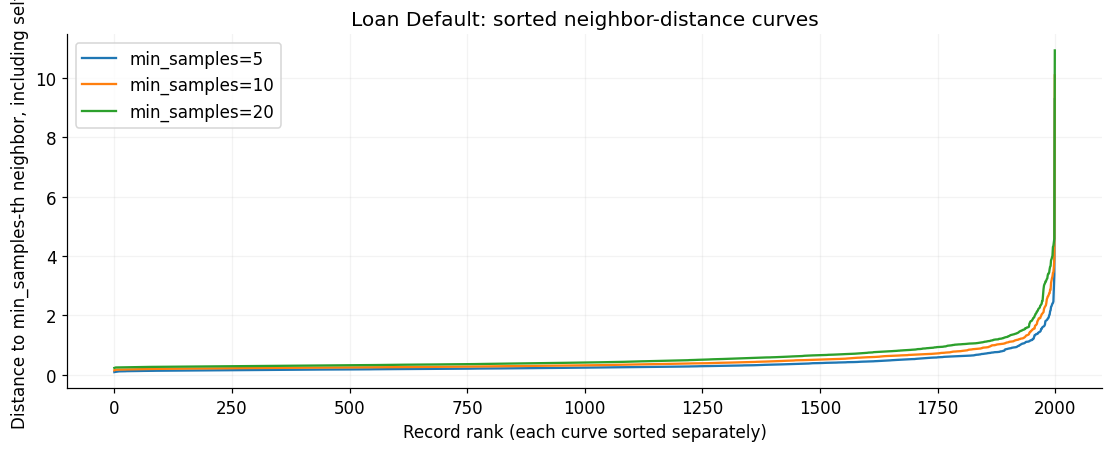

,min_samples,distance quantile,eps,assigned-only silhouette,clusters,noise fraction,smallest cluster,largest share,eligible
candidate,,,,,,,,,
0,5,0.500,0.239,0.023,15,0.390,4,0.556,False
1,5,0.750,0.393,-0.045,7,0.196,3,0.738,False
2,5,0.900,0.627,NaN,1,0.059,1882,0.941,False
3,5,0.950,0.874,NaN,1,0.033,1935,0.968,False
4,10,0.500,0.315,0.040,6,0.374,7,0.601,False
5,10,0.750,0.512,0.297,4,0.170,22,0.760,True
6,10,0.900,0.794,NaN,1,0.051,1899,0.950,False
7,10,0.950,1.086,NaN,1,0.026,1948,0.974,False
8,20,0.500,0.411,NaN,1,0.357,1286,0.643,False


core records      1501
border records     159
noise records      340
total             2000
Name: DBSCAN record types, dtype: int64

**DBSCAN:** eps=0.512, min_samples=10, 4 clusters and 17.0% noise. This is the largest assigned-only silhouette among candidates meeting the stated coverage/size rules. Noise means locally sparse under these parameters; it does not establish fraud or default. Silhouettes excluding noise apply to the assigned subset and cannot be ranked directly against full-sample scores.

In [5]:
# min_samples includes the observation itself; query Z explicitly so self is included.
min_samples_grid = [3, 5, 8] if len(X)<100 else [5, 10, 20]
quantiles = [.50, .75, .90, .95]
db_rows, db_fits = [], {}
fig, ax = plt.subplots(figsize=(10, 4), layout='constrained')
for m in min_samples_grid:
    kth = NearestNeighbors(n_neighbors=m).fit(Z).kneighbors(Z)[0][:,-1]
    ax.plot(np.sort(kth), label=f'min_samples={m}')
    for q in quantiles:
        eps = max(float(np.quantile(kth, q)), np.finfo(float).eps)
        model = DBSCAN(eps=eps, min_samples=m, metric='euclidean').fit(Z)
        stats = cluster_stats(model.labels_)
        idx = len(db_rows)
        db_fits[idx] = model
        db_rows.append({'candidate':idx, 'min_samples':m, 'distance quantile':q, 'eps':eps,
            'assigned-only silhouette':safe_silhouette(Z, model.labels_), **stats})
ax.set(title=f'{plot_label}: sorted neighbor-distance curves', xlabel='Record rank (each curve sorted separately)',
       ylabel='Distance to min_samples-th neighbor, including self')
ax.legend()
plt.show()
db_table = pd.DataFrame(db_rows).set_index('candidate')
db_table['eligible'] = (db_table['clusters'].ge(2) & db_table['smallest cluster'].ge(min_cluster)
                        & db_table['noise fraction'].le(.40) & db_table['assigned-only silhouette'].notna())
display(db_table)
eligible_db = db_table.loc[db_table.eligible]
db_supported = len(eligible_db)>0
if db_supported:
    db_choice = eligible_db.sort_values(['assigned-only silhouette','noise fraction'], ascending=[False,True]).iloc[0]
else:
    # Preserve a genuine failure to find acceptable multiple density clusters.
    db_choice = db_table.sort_values(['noise fraction','candidate']).iloc[0]
db_model = db_fits[int(db_choice.name)]
db_labels = db_model.labels_
core = np.zeros(len(X), dtype=bool)
core[db_model.core_sample_indices_] = True
assigned = db_labels != -1
display(pd.Series({'core records': int(core.sum()), 'border records':int((assigned & ~core).sum()),
    'noise records':int((~assigned).sum()), 'total':len(X)}, name='DBSCAN record types'))
assert core.sum() + (assigned & ~core).sum() + (~assigned).sum() == len(X)
display(Markdown(f'**DBSCAN:** eps={db_choice["eps"]:.3f}, min_samples={int(db_choice["min_samples"])}, '
    f'{int(db_choice["clusters"])} clusters and {db_choice["noise fraction"]:.1%} noise. '
    + ('This is the largest assigned-only silhouette among candidates meeting the stated coverage/size rules.'
       if db_supported else 'No candidate meets the stated multi-cluster, size and coverage rules; this lowest-noise fit is illustrative only.')
    + ' Noise means locally sparse under these parameters; it does not establish fraud or default. '
    'Silhouettes excluding noise apply to the assigned subset and cannot be ranked directly against full-sample scores.'))

### A4. Inspect density sensitivity and profiles

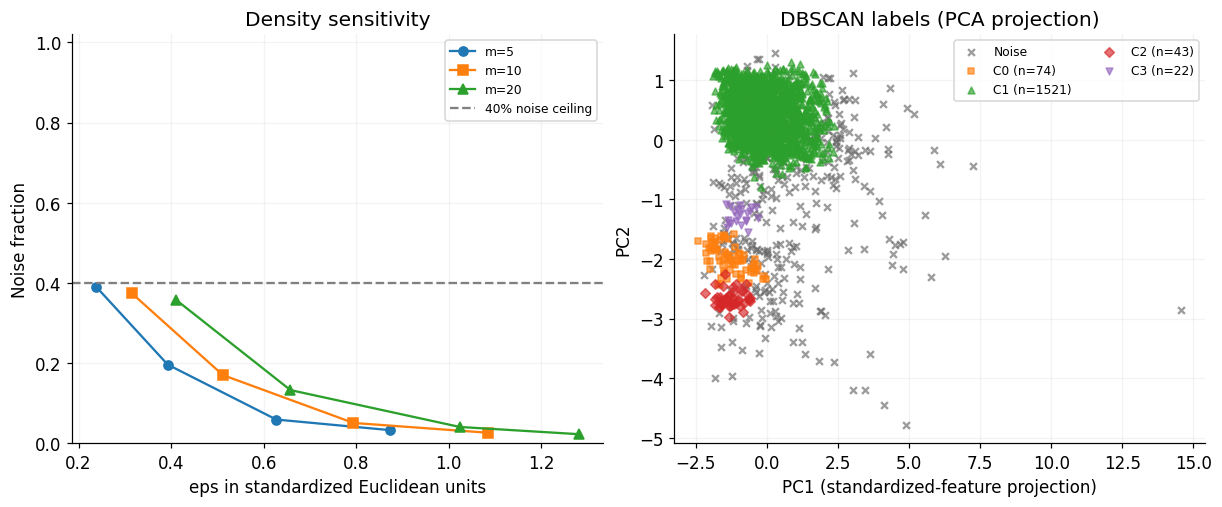

**DBSCAN profile; -1 denotes noise.** Outcome fraction = recorded Status 1; descriptive only.

,n,outcome fraction,median loan_amount,median income,median Credit_Score,median term
cluster,,,,,,
-1,340,0.271,"366,500.000","10,350.000",687.000,300.000
0,74,0.311,"156,500.000","4,560.000",793.000,180.000
1,1521,0.226,"306,500.000","5,280.000",707.000,360.000
2,43,0.209,"176,500.000","4,680.000",570.000,180.000
3,22,0.364,"221,500.000","4,800.000",719.000,240.000


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), layout='constrained')
for m, marker in zip(min_samples_grid, ['o','s','^']):
    part = db_table.loc[db_table['min_samples'].eq(m)]
    axes[0].plot(part['eps'], part['noise fraction'], marker=marker, label=f'm={m}')
axes[0].axhline(.40, linestyle='--', color='gray', label='40% noise ceiling')
axes[0].set(title='Density sensitivity', xlabel='eps in standardized Euclidean units', ylabel='Noise fraction', ylim=(0,1.02))
axes[0].legend(fontsize=8)
scatter_clusters(coords, db_labels, axes[1], 'DBSCAN labels (PCA projection)')
plt.show()
db_profile = profile(db_labels, 'DBSCAN profile; -1 denotes noise')

### A5. Compare HAC linkage and cuts

,linkage,k,silhouette,clusters,noise fraction,smallest cluster,largest share,eligible
0,single,2,0.831,2,0.000,1,1.000,False
1,single,3,0.615,3,0.000,1,0.999,False
2,single,4,0.599,4,0.000,1,0.998,False
3,single,5,0.574,5,0.000,1,0.997,False
4,single,6,0.572,6,0.000,1,0.997,False
5,single,7,0.564,7,0.000,1,0.997,False
6,single,8,0.560,8,0.000,1,0.997,False
7,complete,2,0.831,2,0.000,1,1.000,False
8,complete,3,0.510,3,0.000,1,0.993,False
9,complete,4,0.502,4,0.000,1,0.974,False


,cophenetic correlation
linkage,
single,0.740
complete,0.731
average,0.830
ward,0.541


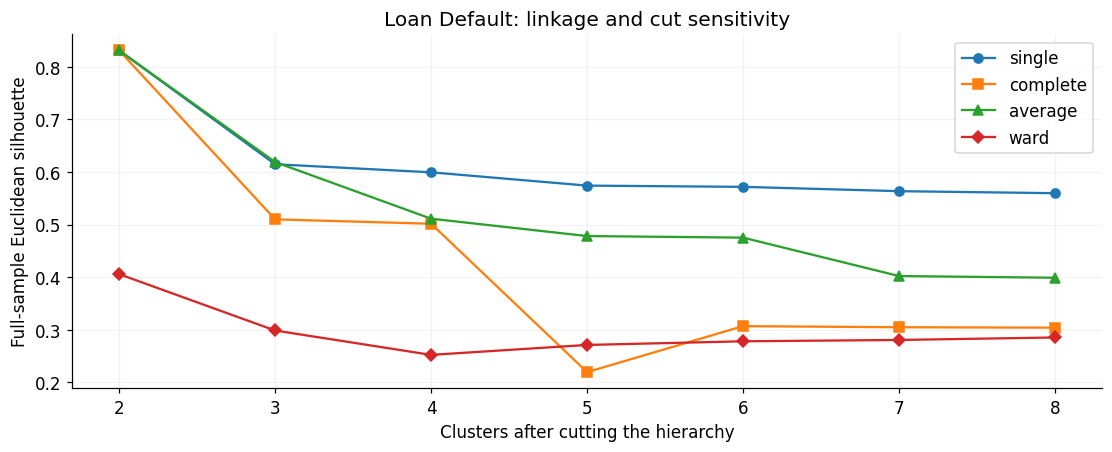

**HAC selection:** ward, k=2, silhouette **0.406**, smallest cluster **279**. Very high scores from tiny outlier clusters can fail the size rule. Cophenetic correlation describes how well tree merge heights preserve original pairwise distances; it does not validate a particular cut or number of clusters.

In [7]:
# Identical sample and geometry across linkages; no outcome enters any selection.
linkages, hac_labels, hac_rows, coph_rows = {}, {}, [], []
condensed = pdist(Z, metric='euclidean')
for method in ['single','complete','average','ward']:
    tree = linkage(condensed, method=method)
    linkages[method] = tree
    correlation, _ = cophenet(tree, condensed)
    coph_rows.append({'linkage':method, 'cophenetic correlation':correlation})
    for k in range(2, 9):
        lab = cut_tree(tree, n_clusters=k).ravel()
        hac_labels[(method,k)] = lab
        hac_rows.append({'linkage':method, 'k':k, 'silhouette':safe_silhouette(Z,lab), **cluster_stats(lab)})
hac_table = pd.DataFrame(hac_rows)
hac_table['eligible'] = hac_table['smallest cluster'].ge(min_cluster)
display(hac_table)
display(pd.DataFrame(coph_rows).set_index('linkage'))
eligible_hac = hac_table.loc[hac_table.eligible]
assert len(eligible_hac), 'No HAC cut meets the cluster-size rule.'
hac_choice = eligible_hac.sort_values(['silhouette','k','linkage'], ascending=[False,True,True]).iloc[0]
chosen_method, chosen_k = hac_choice['linkage'], int(hac_choice['k'])
chosen_labels = hac_labels[(chosen_method,chosen_k)]
fig, ax = plt.subplots(figsize=(10,4), layout='constrained')
for method, marker in zip(linkages,['o','s','^','D']):
    part = hac_table.loc[hac_table.linkage.eq(method)]
    ax.plot(part['k'],part['silhouette'],marker=marker,label=method)
ax.set(title=f'{plot_label}: linkage and cut sensitivity', xlabel='Clusters after cutting the hierarchy', ylabel='Full-sample Euclidean silhouette')
ax.legend()
plt.show()
display(Markdown(f'**HAC selection:** {chosen_method}, k={chosen_k}, silhouette '
    f'**{hac_choice["silhouette"]:.3f}**, smallest cluster **{int(hac_choice["smallest cluster"])}**. '
    'Very high scores from tiny outlier clusters can fail the size rule. Cophenetic correlation describes '
    'how well tree merge heights preserve original pairwise distances; it does not validate a particular cut or number of clusters.'))

### A6. Read the dendrograms

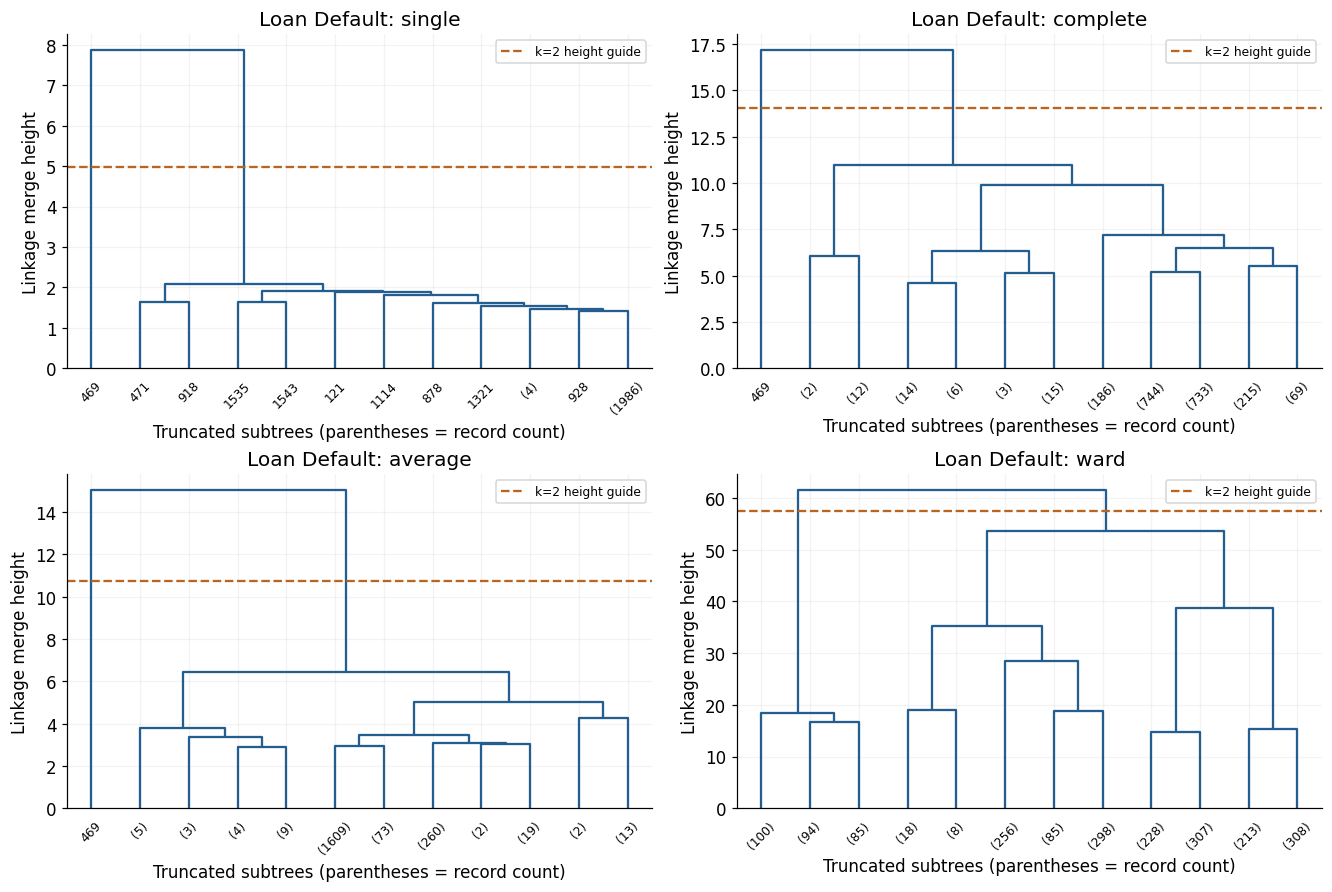

Read bottom to top: leaves/subtrees merge at the vertical-axis height. These are the last 12 subtrees, not 12 individual records. Single linkage joins by the nearest pair and can chain; complete uses the farthest pair; average uses mean pairwise distance. Ward minimizes the increase in within-cluster squared error and requires Euclidean geometry. Heights have linkage-specific meanings, so compare tree structure rather than raw heights across methods. Dashed guides illustrate the selected k; tied merge heights can make a height cut ambiguous, while the analysis uses an exact-k tree cut.

In [8]:
fig, axes = plt.subplots(2,2,figsize=(12,8),layout='constrained')
for ax, (method,tree) in zip(axes.ravel(),linkages.items()):
    dendrogram(tree, truncate_mode='lastp', p=12, show_leaf_counts=True,
        color_threshold=0, above_threshold_color='#245E91', ax=ax)
    # Same chosen k illustrates how merge heights differ, not a shared numeric threshold.
    lower, upper = tree[-chosen_k,2], tree[-chosen_k+1,2]
    height = (lower+upper)/2
    ax.axhline(height,color='#B96520',linestyle='--',label=f'k={chosen_k} height guide')
    ax.set(title=f'{plot_label}: {method}', xlabel='Truncated subtrees (parentheses = record count)',
           ylabel='Linkage merge height')
    ax.tick_params(axis='x',labelsize=8,rotation=45)
    ax.legend(fontsize=8)
plt.show()
display(Markdown('Read bottom to top: leaves/subtrees merge at the vertical-axis height. '
    'These are the last 12 subtrees, not 12 individual records. Single linkage joins by the nearest pair '
    'and can chain; complete uses the farthest pair; average uses mean pairwise distance. Ward minimizes '
    'the increase in within-cluster squared error and requires Euclidean geometry. Heights have linkage-specific '
    'meanings, so compare tree structure rather than raw heights across methods. Dashed guides illustrate '
    'the selected k; tied merge heights can make a height cut ambiguous, while the analysis uses an exact-k tree cut.'))

### A7. Compare algorithms on the same sample

,score population,silhouette,clusters,noise fraction,smallest cluster,largest share
method,,,,,,
K-means,all records,0.416,2,0.000,284,0.858
HAC ward,all records,0.406,2,0.000,279,0.861
DBSCAN,assigned records only,0.297,4,0.170,22,0.760


HAC and k-means partition agreement: **ARI=0.976** on all 2,000 records. The same Euclidean silhouette favors compact groups and is also used for selection, so this is descriptive model exploration rather than an independent validation score.

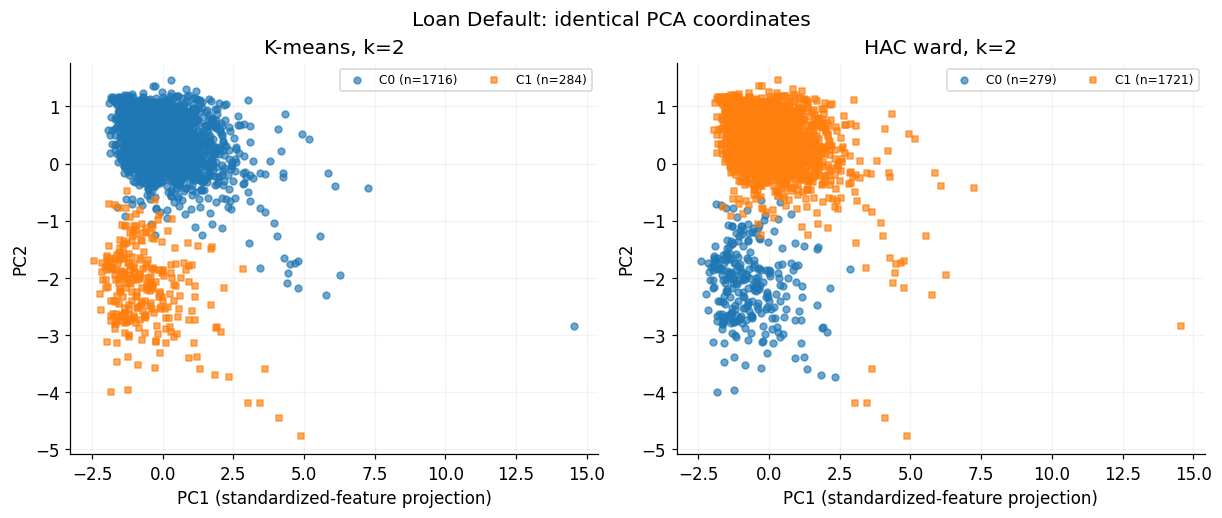

**Selected HAC profile.** Outcome fraction = recorded Status 1; descriptive only.

,n,outcome fraction,median loan_amount,median income,median Credit_Score,median term
cluster,,,,,,
0,279,0.247,"216,500.000","6,060.000",714.000,180.000
1,1721,0.236,"316,500.000","5,580.000",707.000,360.000


**Interpretation:** HAC cluster sizes range from 279 to 1,721; outcome fractions range from 23.6% to 24.7%. These describe selected groups in the same sample, not causal effects, classifier accuracy or confirmed natural customer segments.

In [9]:
# Recompute Week 10's prespecified selection independently; no notebook-to-notebook hidden state.
km_rows, km_models = [], {}
for k in range(2,9):
    model = KMeans(n_clusters=k,n_init=20,random_state=SEED).fit(Z)
    km_models[k] = model
    km_rows.append({'k':k,'silhouette':safe_silhouette(Z,model.labels_), **cluster_stats(model.labels_)})
km_candidates = pd.DataFrame(km_rows).query('`smallest cluster` >= @min_cluster')
km_choice = km_candidates.sort_values(['silhouette','k'],ascending=[False,True]).iloc[0]
km_labels = km_models[int(km_choice['k'])].labels_
comparison_table = pd.DataFrame([
    {'method':'K-means','score population':'all records','silhouette':km_choice['silhouette'],**cluster_stats(km_labels)},
    {'method':f'HAC {chosen_method}','score population':'all records','silhouette':hac_choice['silhouette'],**cluster_stats(chosen_labels)},
    {'method':'DBSCAN' + ('' if db_supported else ' (illustrative)'), 'score population':'assigned records only',
        'silhouette':safe_silhouette(Z,db_labels),**cluster_stats(db_labels)}])
display(comparison_table.set_index('method'))
ari = adjusted_rand_score(km_labels,chosen_labels)
display(Markdown(f'HAC and k-means partition agreement: **ARI={ari:.3f}** on all {len(X):,} records. '
    'The same Euclidean silhouette favors compact groups and is also used for selection, so this is '
    'descriptive model exploration rather than an independent validation score.'))
fig, axes = plt.subplots(1,2,figsize=(11,4.6),layout='constrained')
scatter_clusters(coords,km_labels,axes[0],f'K-means, k={int(km_choice["k"])}')
scatter_clusters(coords,chosen_labels,axes[1],f'HAC {chosen_method}, k={chosen_k}')
fig.suptitle(f'{plot_label}: identical PCA coordinates')
plt.show()
hac_profile = profile(chosen_labels,'Selected HAC profile')
display(Markdown(f'**Interpretation:** HAC cluster sizes range from {hac_profile.n.min():,} '
    f'to {hac_profile.n.max():,}; outcome fractions range from {hac_profile["outcome fraction"].min():.1%} '
    f'to {hac_profile["outcome fraction"].max():.1%}. These describe selected groups in the same sample, '
    'not causal effects, classifier accuracy or confirmed natural customer segments.'))
results.append({'Dataset':plot_label,'n':len(X),'HAC linkage':chosen_method,'HAC k':chosen_k,
    'HAC silhouette':hac_choice['silhouette'],'K-means silhouette':km_choice['silhouette'],
    'HAC/K-means ARI':ari,'DBSCAN clusters':int(db_choice['clusters']),
    'DBSCAN noise':db_choice['noise fraction'],'DBSCAN meets rules':db_supported,
    'sample fingerprint':fingerprint})

## B. LendingClub resolved 2015 36-month loans

### B1. Reconstruct the source cohort

In [10]:
dataset_name = 'accepted_2007_to_2018Q4.csv'
outcome_label = 'charged off among resolved 2015 36-month loans'
USECOLS = ['id', 'loan_amnt', 'annual_inc', 'fico_range_low', 'fico_range_high',
           'dti', 'revol_util', 'open_acc', 'emp_length', 'earliest_cr_line',
           'issue_d', 'loan_status', 'term', 'home_ownership', 'purpose', 'verification_status']
rng = np.random.default_rng(SEED)
frame = pd.DataFrame()
all_rows = vintage_rows = short_term_rows = eligible_rows = 0
status_counts = pd.Series(dtype='int64')
for chunk in pd.read_csv(DATA_DIR / dataset_name, usecols=USECOLS, chunksize=150_000, low_memory=False):
    all_rows += len(chunk)
    cohort = chunk.loc[chunk['issue_d'].astype('str').str.endswith('2015')].copy()
    vintage_rows += len(cohort)
    cohort = cohort.loc[cohort['term'].str.strip().eq('36 months')]
    short_term_rows += len(cohort)
    status_counts = status_counts.add(cohort['loan_status'].value_counts(), fill_value=0)
    cohort = cohort.loc[cohort['loan_status'].isin(['Fully Paid', 'Charged Off'])].copy()
    eligible_rows += len(cohort)
    if len(cohort):
        cohort['_priority'] = rng.random(len(cohort))
        frame = pd.concat([frame, cohort.nsmallest(SAMPLE_SIZE, '_priority')]).nsmallest(SAMPLE_SIZE, '_priority')
frame = frame.drop(columns='_priority').reset_index(drop=True)
assert frame['id'].notna().all() and frame['id'].is_unique
display(pd.Series({'source rows': all_rows, '2015 records': vintage_rows,
    '2015 36-month records': short_term_rows, 'resolved eligible records': eligible_rows,
    'excluded unresolved/other statuses': short_term_rows - eligible_rows,
    'uniform sample': len(frame)}, name='Resolved-outcome cohort'))
display(status_counts.astype(int).rename('2015 36-month records').to_frame())
X = pd.DataFrame({
    'log_loan_amount': np.log1p(frame['loan_amnt'].where(frame['loan_amnt'] > 0)),
    'log_annual_income': np.log1p(frame['annual_inc'].where(frame['annual_inc'] >= 0)),
    'fico_mid': (frame['fico_range_low'] + frame['fico_range_high']) / 2,
    'dti': frame['dti'].where(frame['dti'] >= 0),
    'revol_util': frame['revol_util'].where(frame['revol_util'] >= 0),
    'open_acc': frame['open_acc']})
numeric = list(X.columns)
categorical = ['home_ownership', 'purpose', 'verification_status']
for name in categorical:
    X[name] = frame[name].astype(object).where(frame[name].notna(), np.nan)
y = frame['loan_status'].eq('Charged Off').astype(int)
groups = None

source rows                           2260701
2015 records                           421095
2015 36-month records                  283173
resolved eligible records              283026
excluded unresolved/other statuses        147
uniform sample                          12000
Name: Resolved-outcome cohort, dtype: int64

,2015 36-month records
loan_status,
Charged Off,42132
Current,72
Fully Paid,240894
In Grace Period,9
Late (16-30 days),5
Late (31-120 days),61


### B2. Audit the shared clustering sample

In [11]:
# Use numeric features only: categorical one-hot block weights would add a separate geometry choice.
X = X[numeric].replace([np.inf, -np.inf], np.nan).reset_index(drop=True)
y = y.reset_index(drop=True)
indices = (X.sample(n=CLUSTER_SAMPLE, random_state=SEED).index.to_numpy()
           if len(X) > CLUSTER_SAMPLE else np.arange(len(X)))
X = X.iloc[indices].reset_index(drop=True)
y = y.iloc[indices].reset_index(drop=True)
assert not X.isna().all().any(), 'An entirely missing feature needs a documented decision.'
assert X.select_dtypes('number').shape[1] == X.shape[1]
imputer = SimpleImputer(strategy='median')
raw = imputer.fit_transform(X)
scaler = StandardScaler()
Z = scaler.fit_transform(raw)
assert np.isfinite(Z).all() and len(X) == len(y)
min_cluster = max(3, int(np.ceil(.01*len(X))))
plot_label = {'Loan_Default.csv':'Loan Default', 'accepted_2007_to_2018Q4.csv':'LendingClub',
              'bank_customers.csv':'Bank records'}[dataset_name]
fingerprint = hashlib.sha256(pd.util.hash_pandas_object(X, index=False).values.tobytes()).hexdigest()[:16]
display(pd.Series({'clustering records': len(X), 'numeric dimensions': X.shape[1],
    'duplicate feature rows': X.duplicated().sum(), 'minimum acceptable cluster size': min_cluster,
    'sample feature fingerprint': fingerprint}, name='Clustering sample'))
display(pd.DataFrame({'missing n': X.isna().sum(), 'median': X.median(),
    'minimum': X.min(), 'maximum': X.max(), 'SD before scaling': pd.DataFrame(raw, columns=X.columns).std()}))
pca = PCA(n_components=2, svd_solver='full')
coords = pca.fit_transform(Z)
display(Markdown(f'PCA shows **{pca.explained_variance_ratio_.sum():.1%}** of standardized variance. '
    'All clustering and scores use the full feature space, not this display projection.'))

clustering records                             2000
numeric dimensions                                6
duplicate feature rows                            0
minimum acceptable cluster size                  20
sample feature fingerprint         7fbf4b29f1965fd4
Name: Clustering sample, dtype: object

,missing n,median,minimum,maximum,SD before scaling
log_loan_amount,0,9.210,6.909,10.463,0.688
log_annual_income,0,11.013,9.035,13.422,0.564
fico_mid,0,687.000,662.000,842.000,30.817
dti,0,17.985,0.360,57.140,8.987
revol_util,0,51.350,0.000,118.100,24.316
open_acc,0,11.000,2.000,41.000,5.635


PCA shows **51.9%** of standardized variance. All clustering and scores use the full feature space, not this display projection.

### B3. Explore density and noise

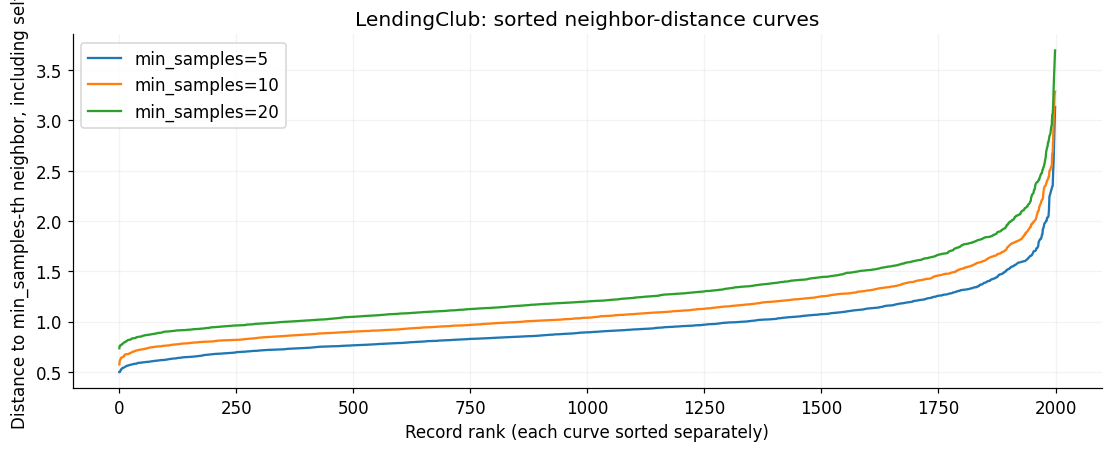

,min_samples,distance quantile,eps,assigned-only silhouette,clusters,noise fraction,smallest cluster,largest share,eligible
candidate,,,,,,,,,
0,5,0.500,0.893,-0.145,11,0.317,3,0.656,False
1,5,0.750,1.073,NaN,1,0.129,1742,0.871,False
2,5,0.900,1.313,NaN,1,0.042,1916,0.958,False
3,5,0.950,1.521,NaN,1,0.017,1967,0.984,False
4,10,0.500,1.039,NaN,1,0.260,1481,0.741,False
5,10,0.750,1.252,NaN,1,0.091,1817,0.908,False
6,10,0.900,1.525,NaN,1,0.025,1949,0.975,False
7,10,0.950,1.746,NaN,1,0.011,1979,0.990,False
8,20,0.500,1.200,NaN,1,0.206,1588,0.794,False


core records      1900
border records      85
noise records       15
total             2000
Name: DBSCAN record types, dtype: int64

**DBSCAN:** eps=1.970, min_samples=20, 1 clusters and 0.8% noise. No candidate meets the stated multi-cluster, size and coverage rules; this lowest-noise fit is illustrative only. Noise means locally sparse under these parameters; it does not establish fraud or default. Silhouettes excluding noise apply to the assigned subset and cannot be ranked directly against full-sample scores.

In [12]:
# min_samples includes the observation itself; query Z explicitly so self is included.
min_samples_grid = [3, 5, 8] if len(X)<100 else [5, 10, 20]
quantiles = [.50, .75, .90, .95]
db_rows, db_fits = [], {}
fig, ax = plt.subplots(figsize=(10, 4), layout='constrained')
for m in min_samples_grid:
    kth = NearestNeighbors(n_neighbors=m).fit(Z).kneighbors(Z)[0][:,-1]
    ax.plot(np.sort(kth), label=f'min_samples={m}')
    for q in quantiles:
        eps = max(float(np.quantile(kth, q)), np.finfo(float).eps)
        model = DBSCAN(eps=eps, min_samples=m, metric='euclidean').fit(Z)
        stats = cluster_stats(model.labels_)
        idx = len(db_rows)
        db_fits[idx] = model
        db_rows.append({'candidate':idx, 'min_samples':m, 'distance quantile':q, 'eps':eps,
            'assigned-only silhouette':safe_silhouette(Z, model.labels_), **stats})
ax.set(title=f'{plot_label}: sorted neighbor-distance curves', xlabel='Record rank (each curve sorted separately)',
       ylabel='Distance to min_samples-th neighbor, including self')
ax.legend()
plt.show()
db_table = pd.DataFrame(db_rows).set_index('candidate')
db_table['eligible'] = (db_table['clusters'].ge(2) & db_table['smallest cluster'].ge(min_cluster)
                        & db_table['noise fraction'].le(.40) & db_table['assigned-only silhouette'].notna())
display(db_table)
eligible_db = db_table.loc[db_table.eligible]
db_supported = len(eligible_db)>0
if db_supported:
    db_choice = eligible_db.sort_values(['assigned-only silhouette','noise fraction'], ascending=[False,True]).iloc[0]
else:
    # Preserve a genuine failure to find acceptable multiple density clusters.
    db_choice = db_table.sort_values(['noise fraction','candidate']).iloc[0]
db_model = db_fits[int(db_choice.name)]
db_labels = db_model.labels_
core = np.zeros(len(X), dtype=bool)
core[db_model.core_sample_indices_] = True
assigned = db_labels != -1
display(pd.Series({'core records': int(core.sum()), 'border records':int((assigned & ~core).sum()),
    'noise records':int((~assigned).sum()), 'total':len(X)}, name='DBSCAN record types'))
assert core.sum() + (assigned & ~core).sum() + (~assigned).sum() == len(X)
display(Markdown(f'**DBSCAN:** eps={db_choice["eps"]:.3f}, min_samples={int(db_choice["min_samples"])}, '
    f'{int(db_choice["clusters"])} clusters and {db_choice["noise fraction"]:.1%} noise. '
    + ('This is the largest assigned-only silhouette among candidates meeting the stated coverage/size rules.'
       if db_supported else 'No candidate meets the stated multi-cluster, size and coverage rules; this lowest-noise fit is illustrative only.')
    + ' Noise means locally sparse under these parameters; it does not establish fraud or default. '
    'Silhouettes excluding noise apply to the assigned subset and cannot be ranked directly against full-sample scores.'))

### B4. Inspect density sensitivity and profiles

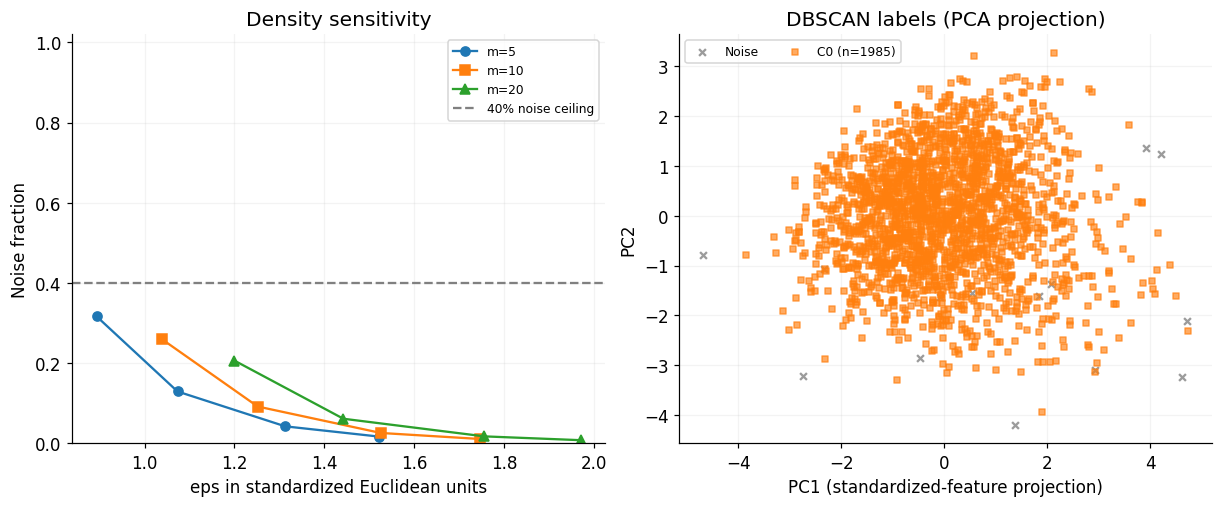

**DBSCAN profile; -1 denotes noise.** Outcome fraction = charged off among resolved 2015 36-month loans; descriptive only.

,n,outcome fraction,median log_loan_amount,median log_annual_income,median fico_mid,median dti,median revol_util,median open_acc
cluster,,,,,,,,
-1,15,0.000,9.616,10.820,732.000,29.750,31.400,28.000
0,1985,0.133,9.210,11.019,687.000,17.940,51.600,11.000


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), layout='constrained')
for m, marker in zip(min_samples_grid, ['o','s','^']):
    part = db_table.loc[db_table['min_samples'].eq(m)]
    axes[0].plot(part['eps'], part['noise fraction'], marker=marker, label=f'm={m}')
axes[0].axhline(.40, linestyle='--', color='gray', label='40% noise ceiling')
axes[0].set(title='Density sensitivity', xlabel='eps in standardized Euclidean units', ylabel='Noise fraction', ylim=(0,1.02))
axes[0].legend(fontsize=8)
scatter_clusters(coords, db_labels, axes[1], 'DBSCAN labels (PCA projection)')
plt.show()
db_profile = profile(db_labels, 'DBSCAN profile; -1 denotes noise')

### B5. Compare HAC linkage and cuts

,linkage,k,silhouette,clusters,noise fraction,smallest cluster,largest share,eligible
0,single,2,0.429,2,0.000,1,1.000,False
1,single,3,0.413,3,0.000,1,0.999,False
2,single,4,0.358,4,0.000,1,0.999,False
3,single,5,0.343,5,0.000,1,0.998,False
4,single,6,0.297,6,0.000,1,0.997,False
5,single,7,0.265,7,0.000,1,0.996,False
6,single,8,0.242,8,0.000,1,0.996,False
7,complete,2,0.117,2,0.000,667,0.666,True
8,complete,3,0.103,3,0.000,40,0.666,True
9,complete,4,0.070,4,0.000,10,0.661,False


,cophenetic correlation
linkage,
single,0.593
complete,0.349
average,0.600
ward,0.365


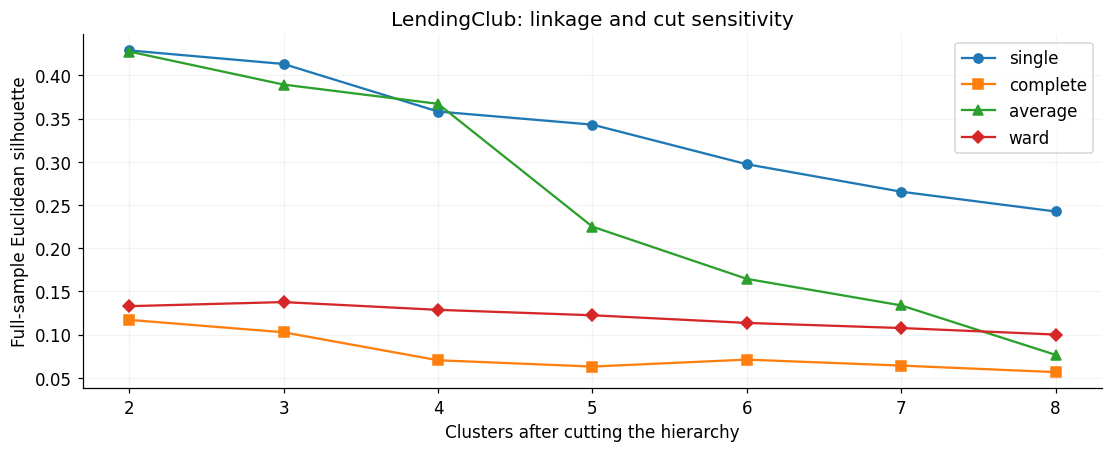

**HAC selection:** ward, k=3, silhouette **0.138**, smallest cluster **197**. Very high scores from tiny outlier clusters can fail the size rule. Cophenetic correlation describes how well tree merge heights preserve original pairwise distances; it does not validate a particular cut or number of clusters.

In [14]:
# Identical sample and geometry across linkages; no outcome enters any selection.
linkages, hac_labels, hac_rows, coph_rows = {}, {}, [], []
condensed = pdist(Z, metric='euclidean')
for method in ['single','complete','average','ward']:
    tree = linkage(condensed, method=method)
    linkages[method] = tree
    correlation, _ = cophenet(tree, condensed)
    coph_rows.append({'linkage':method, 'cophenetic correlation':correlation})
    for k in range(2, 9):
        lab = cut_tree(tree, n_clusters=k).ravel()
        hac_labels[(method,k)] = lab
        hac_rows.append({'linkage':method, 'k':k, 'silhouette':safe_silhouette(Z,lab), **cluster_stats(lab)})
hac_table = pd.DataFrame(hac_rows)
hac_table['eligible'] = hac_table['smallest cluster'].ge(min_cluster)
display(hac_table)
display(pd.DataFrame(coph_rows).set_index('linkage'))
eligible_hac = hac_table.loc[hac_table.eligible]
assert len(eligible_hac), 'No HAC cut meets the cluster-size rule.'
hac_choice = eligible_hac.sort_values(['silhouette','k','linkage'], ascending=[False,True,True]).iloc[0]
chosen_method, chosen_k = hac_choice['linkage'], int(hac_choice['k'])
chosen_labels = hac_labels[(chosen_method,chosen_k)]
fig, ax = plt.subplots(figsize=(10,4), layout='constrained')
for method, marker in zip(linkages,['o','s','^','D']):
    part = hac_table.loc[hac_table.linkage.eq(method)]
    ax.plot(part['k'],part['silhouette'],marker=marker,label=method)
ax.set(title=f'{plot_label}: linkage and cut sensitivity', xlabel='Clusters after cutting the hierarchy', ylabel='Full-sample Euclidean silhouette')
ax.legend()
plt.show()
display(Markdown(f'**HAC selection:** {chosen_method}, k={chosen_k}, silhouette '
    f'**{hac_choice["silhouette"]:.3f}**, smallest cluster **{int(hac_choice["smallest cluster"])}**. '
    'Very high scores from tiny outlier clusters can fail the size rule. Cophenetic correlation describes '
    'how well tree merge heights preserve original pairwise distances; it does not validate a particular cut or number of clusters.'))

### B6. Read the dendrograms

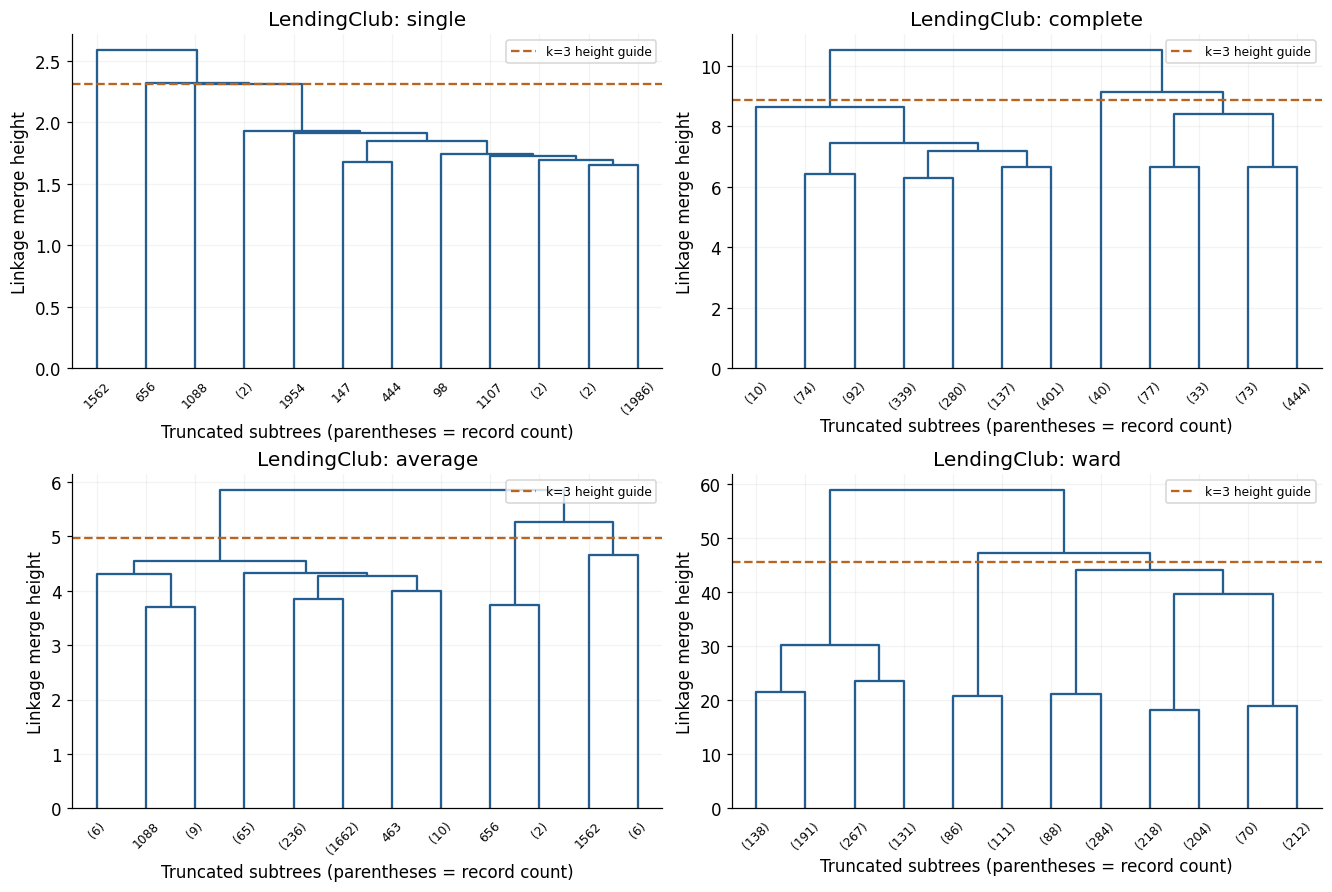

Read bottom to top: leaves/subtrees merge at the vertical-axis height. These are the last 12 subtrees, not 12 individual records. Single linkage joins by the nearest pair and can chain; complete uses the farthest pair; average uses mean pairwise distance. Ward minimizes the increase in within-cluster squared error and requires Euclidean geometry. Heights have linkage-specific meanings, so compare tree structure rather than raw heights across methods. Dashed guides illustrate the selected k; tied merge heights can make a height cut ambiguous, while the analysis uses an exact-k tree cut.

In [15]:
fig, axes = plt.subplots(2,2,figsize=(12,8),layout='constrained')
for ax, (method,tree) in zip(axes.ravel(),linkages.items()):
    dendrogram(tree, truncate_mode='lastp', p=12, show_leaf_counts=True,
        color_threshold=0, above_threshold_color='#245E91', ax=ax)
    # Same chosen k illustrates how merge heights differ, not a shared numeric threshold.
    lower, upper = tree[-chosen_k,2], tree[-chosen_k+1,2]
    height = (lower+upper)/2
    ax.axhline(height,color='#B96520',linestyle='--',label=f'k={chosen_k} height guide')
    ax.set(title=f'{plot_label}: {method}', xlabel='Truncated subtrees (parentheses = record count)',
           ylabel='Linkage merge height')
    ax.tick_params(axis='x',labelsize=8,rotation=45)
    ax.legend(fontsize=8)
plt.show()
display(Markdown('Read bottom to top: leaves/subtrees merge at the vertical-axis height. '
    'These are the last 12 subtrees, not 12 individual records. Single linkage joins by the nearest pair '
    'and can chain; complete uses the farthest pair; average uses mean pairwise distance. Ward minimizes '
    'the increase in within-cluster squared error and requires Euclidean geometry. Heights have linkage-specific '
    'meanings, so compare tree structure rather than raw heights across methods. Dashed guides illustrate '
    'the selected k; tied merge heights can make a height cut ambiguous, while the analysis uses an exact-k tree cut.'))

### B7. Compare algorithms on the same sample

,score population,silhouette,clusters,noise fraction,smallest cluster,largest share
method,,,,,,
K-means,all records,0.177,2,0.000,902,0.549
HAC ward,all records,0.138,3,0.000,197,0.538
DBSCAN (illustrative),assigned records only,NaN,1,0.007,1985,0.993


HAC and k-means partition agreement: **ARI=0.270** on all 2,000 records. The same Euclidean silhouette favors compact groups and is also used for selection, so this is descriptive model exploration rather than an independent validation score.

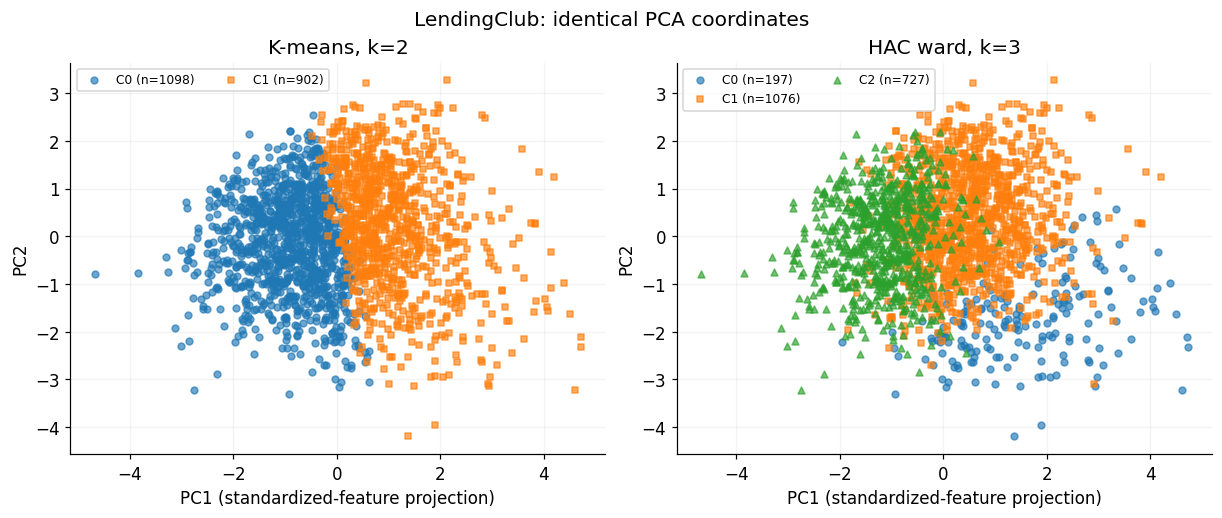

**Selected HAC profile.** Outcome fraction = charged off among resolved 2015 36-month loans; descriptive only.

,n,outcome fraction,median log_loan_amount,median log_annual_income,median fico_mid,median dti,median revol_util,median open_acc
cluster,,,,,,,,
0,197,0.066,9.306,11.156,757.000,14.430,22.400,12.000
1,1076,0.127,9.616,11.225,689.500,14.855,51.200,11.000
2,727,0.157,8.882,10.645,677.000,24.450,60.200,10.000


**Interpretation:** HAC cluster sizes range from 197 to 1,076; outcome fractions range from 6.6% to 15.7%. These describe selected groups in the same sample, not causal effects, classifier accuracy or confirmed natural customer segments.

In [16]:
# Recompute Week 10's prespecified selection independently; no notebook-to-notebook hidden state.
km_rows, km_models = [], {}
for k in range(2,9):
    model = KMeans(n_clusters=k,n_init=20,random_state=SEED).fit(Z)
    km_models[k] = model
    km_rows.append({'k':k,'silhouette':safe_silhouette(Z,model.labels_), **cluster_stats(model.labels_)})
km_candidates = pd.DataFrame(km_rows).query('`smallest cluster` >= @min_cluster')
km_choice = km_candidates.sort_values(['silhouette','k'],ascending=[False,True]).iloc[0]
km_labels = km_models[int(km_choice['k'])].labels_
comparison_table = pd.DataFrame([
    {'method':'K-means','score population':'all records','silhouette':km_choice['silhouette'],**cluster_stats(km_labels)},
    {'method':f'HAC {chosen_method}','score population':'all records','silhouette':hac_choice['silhouette'],**cluster_stats(chosen_labels)},
    {'method':'DBSCAN' + ('' if db_supported else ' (illustrative)'), 'score population':'assigned records only',
        'silhouette':safe_silhouette(Z,db_labels),**cluster_stats(db_labels)}])
display(comparison_table.set_index('method'))
ari = adjusted_rand_score(km_labels,chosen_labels)
display(Markdown(f'HAC and k-means partition agreement: **ARI={ari:.3f}** on all {len(X):,} records. '
    'The same Euclidean silhouette favors compact groups and is also used for selection, so this is '
    'descriptive model exploration rather than an independent validation score.'))
fig, axes = plt.subplots(1,2,figsize=(11,4.6),layout='constrained')
scatter_clusters(coords,km_labels,axes[0],f'K-means, k={int(km_choice["k"])}')
scatter_clusters(coords,chosen_labels,axes[1],f'HAC {chosen_method}, k={chosen_k}')
fig.suptitle(f'{plot_label}: identical PCA coordinates')
plt.show()
hac_profile = profile(chosen_labels,'Selected HAC profile')
display(Markdown(f'**Interpretation:** HAC cluster sizes range from {hac_profile.n.min():,} '
    f'to {hac_profile.n.max():,}; outcome fractions range from {hac_profile["outcome fraction"].min():.1%} '
    f'to {hac_profile["outcome fraction"].max():.1%}. These describe selected groups in the same sample, '
    'not causal effects, classifier accuracy or confirmed natural customer segments.'))
results.append({'Dataset':plot_label,'n':len(X),'HAC linkage':chosen_method,'HAC k':chosen_k,
    'HAC silhouette':hac_choice['silhouette'],'K-means silhouette':km_choice['silhouette'],
    'HAC/K-means ARI':ari,'DBSCAN clusters':int(db_choice['clusters']),
    'DBSCAN noise':db_choice['noise fraction'],'DBSCAN meets rules':db_supported,
    'sample fingerprint':fingerprint})

## C. Bank age and historical tenure

### C1. Reconstruct the source cohort

In [17]:
dataset_name = 'bank_customers.csv'
source_frame = pd.read_csv(DATA_DIR / dataset_name, usecols=lambda name: name != 'SSN')
AS_OF = pd.Timestamp('2026-09-26')
birth_text = source_frame['BirthDate'].astype('string').str.strip()
partial_birth = birth_text.str.fullmatch(r'\d{4}', na=False)
birth = pd.to_datetime(birth_text.mask(partial_birth), format='mixed', errors='coerce')
opened = pd.to_datetime(source_frame['AccountOpened'], format='mixed', errors='coerce')
valid_type = source_frame['AccountType'].isin(['checking', 'savings', 'cd'])
eligible = (birth.notna() & opened.notna() & birth.le(AS_OF) & opened.le(AS_OF)
            & opened.ge(birth) & valid_type)
# Reason flags overlap; the union, not their sum, determines exclusions.
display(pd.Series({'source records': len(source_frame),
    'missing/invalid/partial birth date': birth.isna().sum(),
    'missing/invalid opening date': opened.isna().sum(),
    'future opening date': opened.gt(AS_OF).sum(),
    'opening before exact birth date': opened.lt(birth).sum(),
    'missing/unrecognized account type': (~valid_type).sum(),
    'eligible records': eligible.sum(), 'excluded union': (~eligible).sum()}, name='Bank eligibility audit'))
frame = source_frame.loc[eligible].copy()
frame['age_years'] = (AS_OF - birth.loc[eligible]).dt.days / 365.25
frame['tenure_years'] = (AS_OF - opened.loc[eligible]).dt.days / 365.25
# Repeated AccountID values are conservatively grouped, even though this file
# does not document whether they represent shared accounts or data-quality issues.
frame['_group'] = frame['AccountID'].astype('string')
frame['_group'] = frame['_group'].fillna(pd.Series(
    ['missing_account_' + str(i) for i in frame.index], index=frame.index))
frame = frame.reset_index(drop=True)
groups = frame['_group']
assert len(frame) >= 20
display(frame['AccountType'].value_counts().rename('eligible records').to_frame())
# BirthDate, CustomerID, AccountID, and SSN are never displayed or used as model features.

outcome_label = 'checking account versus savings/CD'
X = frame[['age_years', 'tenure_years']].copy()
y = frame['AccountType'].eq('checking').astype(int)
numeric, categorical = list(X.columns), []

source records                        100
missing/invalid/partial birth date      3
missing/invalid opening date            1
future opening date                    59
opening before exact birth date         0
missing/unrecognized account type       1
eligible records                       39
excluded union                         61
Name: Bank eligibility audit, dtype: int64

,eligible records
AccountType,
checking,16
savings,15
cd,8


### C2. Audit the shared clustering sample

In [18]:
# Use numeric features only: categorical one-hot block weights would add a separate geometry choice.
X = X[numeric].replace([np.inf, -np.inf], np.nan).reset_index(drop=True)
y = y.reset_index(drop=True)
indices = (X.sample(n=CLUSTER_SAMPLE, random_state=SEED).index.to_numpy()
           if len(X) > CLUSTER_SAMPLE else np.arange(len(X)))
X = X.iloc[indices].reset_index(drop=True)
y = y.iloc[indices].reset_index(drop=True)
assert not X.isna().all().any(), 'An entirely missing feature needs a documented decision.'
assert X.select_dtypes('number').shape[1] == X.shape[1]
imputer = SimpleImputer(strategy='median')
raw = imputer.fit_transform(X)
scaler = StandardScaler()
Z = scaler.fit_transform(raw)
assert np.isfinite(Z).all() and len(X) == len(y)
min_cluster = max(3, int(np.ceil(.01*len(X))))
plot_label = {'Loan_Default.csv':'Loan Default', 'accepted_2007_to_2018Q4.csv':'LendingClub',
              'bank_customers.csv':'Bank records'}[dataset_name]
fingerprint = hashlib.sha256(pd.util.hash_pandas_object(X, index=False).values.tobytes()).hexdigest()[:16]
display(pd.Series({'clustering records': len(X), 'numeric dimensions': X.shape[1],
    'duplicate feature rows': X.duplicated().sum(), 'minimum acceptable cluster size': min_cluster,
    'sample feature fingerprint': fingerprint}, name='Clustering sample'))
display(pd.DataFrame({'missing n': X.isna().sum(), 'median': X.median(),
    'minimum': X.min(), 'maximum': X.max(), 'SD before scaling': pd.DataFrame(raw, columns=X.columns).std()}))
pca = PCA(n_components=2, svd_solver='full')
coords = pca.fit_transform(Z)
display(Markdown(f'PCA shows **{pca.explained_variance_ratio_.sum():.1%}** of standardized variance. '
    'All clustering and scores use the full feature space, not this display projection.'))

clustering records                               39
numeric dimensions                                2
duplicate feature rows                            0
minimum acceptable cluster size                   3
sample feature fingerprint         58d445e664cb6d2b
Name: Clustering sample, dtype: object

,missing n,median,minimum,maximum,SD before scaling
age_years,0,49.780,13.569,74.667,17.951
tenure_years,0,18.051,1.399,73.394,18.164


PCA shows **100.0%** of standardized variance. All clustering and scores use the full feature space, not this display projection.

In [19]:
display(pd.Series({'eligible bank records':len(frame), 'distinct account groups':groups.nunique(),
    'records beyond one per group':len(frame)-groups.nunique()}, name='Account repetition audit'))
display(Markdown('Repeated account groups retain their original row weight in this exploratory record-level study. '
    'With only 39 eligible records, bank clusters are a methods demonstration and do not establish population segments.'))

eligible bank records           39
distinct account groups         36
records beyond one per group     3
Name: Account repetition audit, dtype: int64

Repeated account groups retain their original row weight in this exploratory record-level study. With only 39 eligible records, bank clusters are a methods demonstration and do not establish population segments.

### C3. Explore density and noise

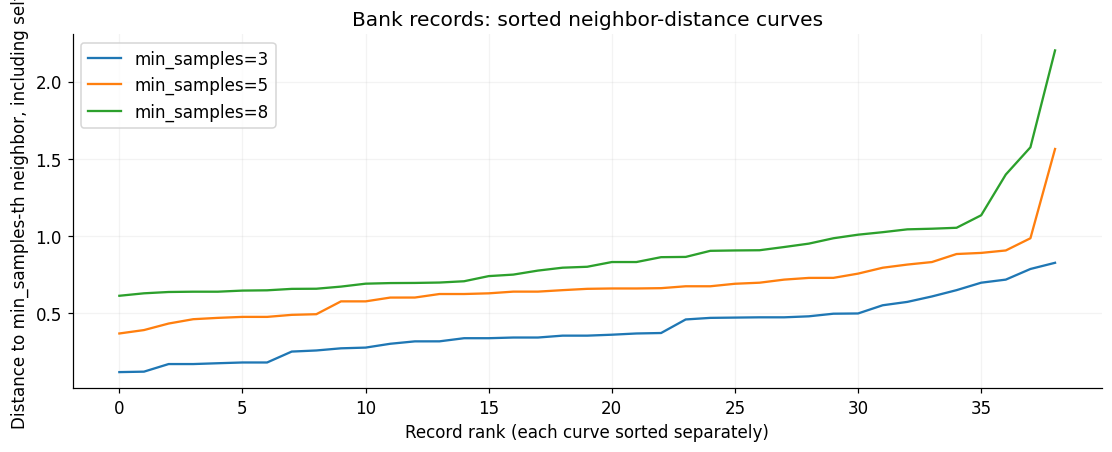

,min_samples,distance quantile,eps,assigned-only silhouette,clusters,noise fraction,smallest cluster,largest share,eligible
candidate,,,,,,,,,
0,3,0.500,0.355,0.462,5,0.385,3,0.231,True
1,3,0.750,0.489,0.403,5,0.103,4,0.385,True
2,3,0.900,0.659,0.360,3,0.051,4,0.692,True
3,3,0.950,0.725,NaN,1,0.000,39,1.000,False
4,5,0.500,0.658,0.378,2,0.154,6,0.692,True
5,5,0.750,0.729,NaN,1,0.103,35,0.897,False
6,5,0.900,0.885,NaN,1,0.000,39,1.000,False
7,5,0.950,0.914,NaN,1,0.000,39,1.000,False
8,8,0.500,0.801,NaN,1,0.179,32,0.821,False


core records      20
border records     4
noise records     15
total             39
Name: DBSCAN record types, dtype: int64

**DBSCAN:** eps=0.355, min_samples=3, 5 clusters and 38.5% noise. This is the largest assigned-only silhouette among candidates meeting the stated coverage/size rules. Noise means locally sparse under these parameters; it does not establish fraud or default. Silhouettes excluding noise apply to the assigned subset and cannot be ranked directly against full-sample scores.

In [20]:
# min_samples includes the observation itself; query Z explicitly so self is included.
min_samples_grid = [3, 5, 8] if len(X)<100 else [5, 10, 20]
quantiles = [.50, .75, .90, .95]
db_rows, db_fits = [], {}
fig, ax = plt.subplots(figsize=(10, 4), layout='constrained')
for m in min_samples_grid:
    kth = NearestNeighbors(n_neighbors=m).fit(Z).kneighbors(Z)[0][:,-1]
    ax.plot(np.sort(kth), label=f'min_samples={m}')
    for q in quantiles:
        eps = max(float(np.quantile(kth, q)), np.finfo(float).eps)
        model = DBSCAN(eps=eps, min_samples=m, metric='euclidean').fit(Z)
        stats = cluster_stats(model.labels_)
        idx = len(db_rows)
        db_fits[idx] = model
        db_rows.append({'candidate':idx, 'min_samples':m, 'distance quantile':q, 'eps':eps,
            'assigned-only silhouette':safe_silhouette(Z, model.labels_), **stats})
ax.set(title=f'{plot_label}: sorted neighbor-distance curves', xlabel='Record rank (each curve sorted separately)',
       ylabel='Distance to min_samples-th neighbor, including self')
ax.legend()
plt.show()
db_table = pd.DataFrame(db_rows).set_index('candidate')
db_table['eligible'] = (db_table['clusters'].ge(2) & db_table['smallest cluster'].ge(min_cluster)
                        & db_table['noise fraction'].le(.40) & db_table['assigned-only silhouette'].notna())
display(db_table)
eligible_db = db_table.loc[db_table.eligible]
db_supported = len(eligible_db)>0
if db_supported:
    db_choice = eligible_db.sort_values(['assigned-only silhouette','noise fraction'], ascending=[False,True]).iloc[0]
else:
    # Preserve a genuine failure to find acceptable multiple density clusters.
    db_choice = db_table.sort_values(['noise fraction','candidate']).iloc[0]
db_model = db_fits[int(db_choice.name)]
db_labels = db_model.labels_
core = np.zeros(len(X), dtype=bool)
core[db_model.core_sample_indices_] = True
assigned = db_labels != -1
display(pd.Series({'core records': int(core.sum()), 'border records':int((assigned & ~core).sum()),
    'noise records':int((~assigned).sum()), 'total':len(X)}, name='DBSCAN record types'))
assert core.sum() + (assigned & ~core).sum() + (~assigned).sum() == len(X)
display(Markdown(f'**DBSCAN:** eps={db_choice["eps"]:.3f}, min_samples={int(db_choice["min_samples"])}, '
    f'{int(db_choice["clusters"])} clusters and {db_choice["noise fraction"]:.1%} noise. '
    + ('This is the largest assigned-only silhouette among candidates meeting the stated coverage/size rules.'
       if db_supported else 'No candidate meets the stated multi-cluster, size and coverage rules; this lowest-noise fit is illustrative only.')
    + ' Noise means locally sparse under these parameters; it does not establish fraud or default. '
    'Silhouettes excluding noise apply to the assigned subset and cannot be ranked directly against full-sample scores.'))

### C4. Inspect density sensitivity and profiles

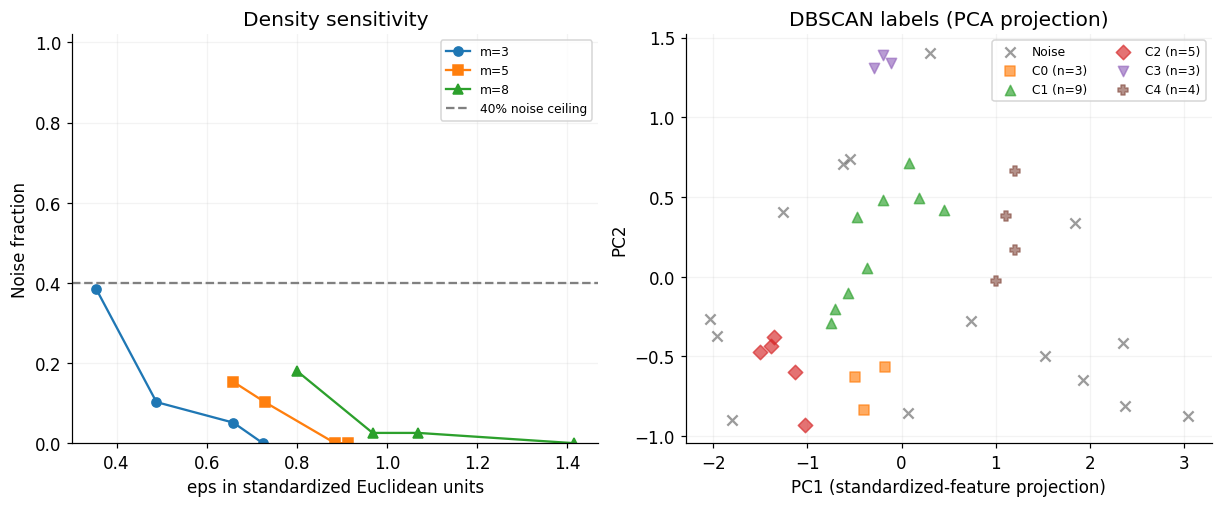

**DBSCAN profile; -1 denotes noise.** Outcome fraction = checking account versus savings/CD; descriptive only.

,n,outcome fraction,median age_years,median tenure_years
cluster,,,,
-1,15,0.333,53.128,35.513
0,3,0.667,33.388,28.726
1,9,0.667,46.283,17.985
2,5,0.000,24.597,11.784
3,3,0.667,62.357,3.734
4,4,0.250,65.320,34.957


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), layout='constrained')
for m, marker in zip(min_samples_grid, ['o','s','^']):
    part = db_table.loc[db_table['min_samples'].eq(m)]
    axes[0].plot(part['eps'], part['noise fraction'], marker=marker, label=f'm={m}')
axes[0].axhline(.40, linestyle='--', color='gray', label='40% noise ceiling')
axes[0].set(title='Density sensitivity', xlabel='eps in standardized Euclidean units', ylabel='Noise fraction', ylim=(0,1.02))
axes[0].legend(fontsize=8)
scatter_clusters(coords, db_labels, axes[1], 'DBSCAN labels (PCA projection)')
plt.show()
db_profile = profile(db_labels, 'DBSCAN profile; -1 denotes noise')

### C5. Compare HAC linkage and cuts

,linkage,k,silhouette,clusters,noise fraction,smallest cluster,largest share,eligible
0,single,2,-0.099,2,0.000,1,0.974,False
1,single,3,-0.043,3,0.000,1,0.846,False
2,single,4,-0.111,4,0.000,1,0.846,False
3,single,5,0.019,5,0.000,1,0.692,False
4,single,6,-0.020,6,0.000,1,0.692,False
5,single,7,0.101,7,0.000,1,0.590,False
6,single,8,0.056,8,0.000,1,0.564,False
7,complete,2,0.488,2,0.000,11,0.718,True
8,complete,3,0.397,3,0.000,7,0.538,True
9,complete,4,0.379,4,0.000,3,0.538,True


,cophenetic correlation
linkage,
single,0.628
complete,0.719
average,0.731
ward,0.722


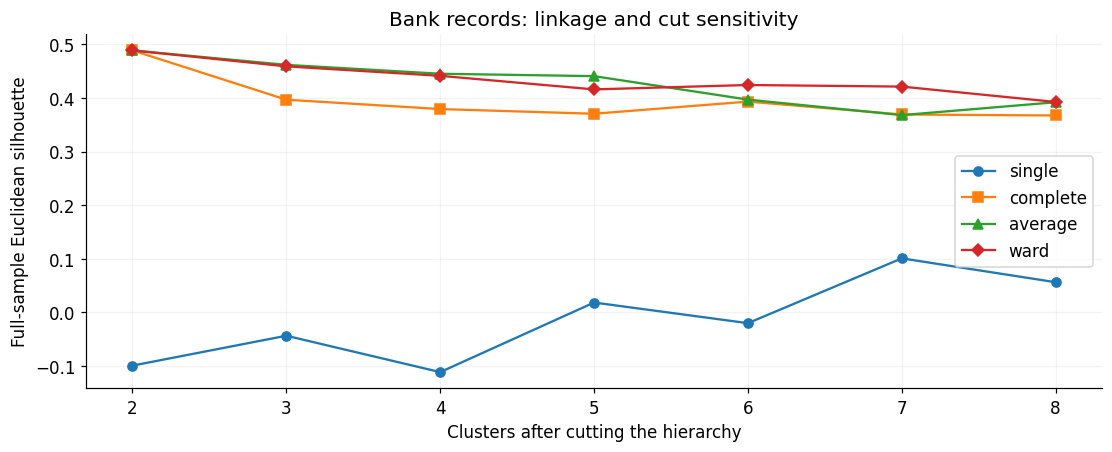

**HAC selection:** average, k=2, silhouette **0.488**, smallest cluster **11**. Very high scores from tiny outlier clusters can fail the size rule. Cophenetic correlation describes how well tree merge heights preserve original pairwise distances; it does not validate a particular cut or number of clusters.

In [22]:
# Identical sample and geometry across linkages; no outcome enters any selection.
linkages, hac_labels, hac_rows, coph_rows = {}, {}, [], []
condensed = pdist(Z, metric='euclidean')
for method in ['single','complete','average','ward']:
    tree = linkage(condensed, method=method)
    linkages[method] = tree
    correlation, _ = cophenet(tree, condensed)
    coph_rows.append({'linkage':method, 'cophenetic correlation':correlation})
    for k in range(2, 9):
        lab = cut_tree(tree, n_clusters=k).ravel()
        hac_labels[(method,k)] = lab
        hac_rows.append({'linkage':method, 'k':k, 'silhouette':safe_silhouette(Z,lab), **cluster_stats(lab)})
hac_table = pd.DataFrame(hac_rows)
hac_table['eligible'] = hac_table['smallest cluster'].ge(min_cluster)
display(hac_table)
display(pd.DataFrame(coph_rows).set_index('linkage'))
eligible_hac = hac_table.loc[hac_table.eligible]
assert len(eligible_hac), 'No HAC cut meets the cluster-size rule.'
hac_choice = eligible_hac.sort_values(['silhouette','k','linkage'], ascending=[False,True,True]).iloc[0]
chosen_method, chosen_k = hac_choice['linkage'], int(hac_choice['k'])
chosen_labels = hac_labels[(chosen_method,chosen_k)]
fig, ax = plt.subplots(figsize=(10,4), layout='constrained')
for method, marker in zip(linkages,['o','s','^','D']):
    part = hac_table.loc[hac_table.linkage.eq(method)]
    ax.plot(part['k'],part['silhouette'],marker=marker,label=method)
ax.set(title=f'{plot_label}: linkage and cut sensitivity', xlabel='Clusters after cutting the hierarchy', ylabel='Full-sample Euclidean silhouette')
ax.legend()
plt.show()
display(Markdown(f'**HAC selection:** {chosen_method}, k={chosen_k}, silhouette '
    f'**{hac_choice["silhouette"]:.3f}**, smallest cluster **{int(hac_choice["smallest cluster"])}**. '
    'Very high scores from tiny outlier clusters can fail the size rule. Cophenetic correlation describes '
    'how well tree merge heights preserve original pairwise distances; it does not validate a particular cut or number of clusters.'))

### C6. Read the dendrograms

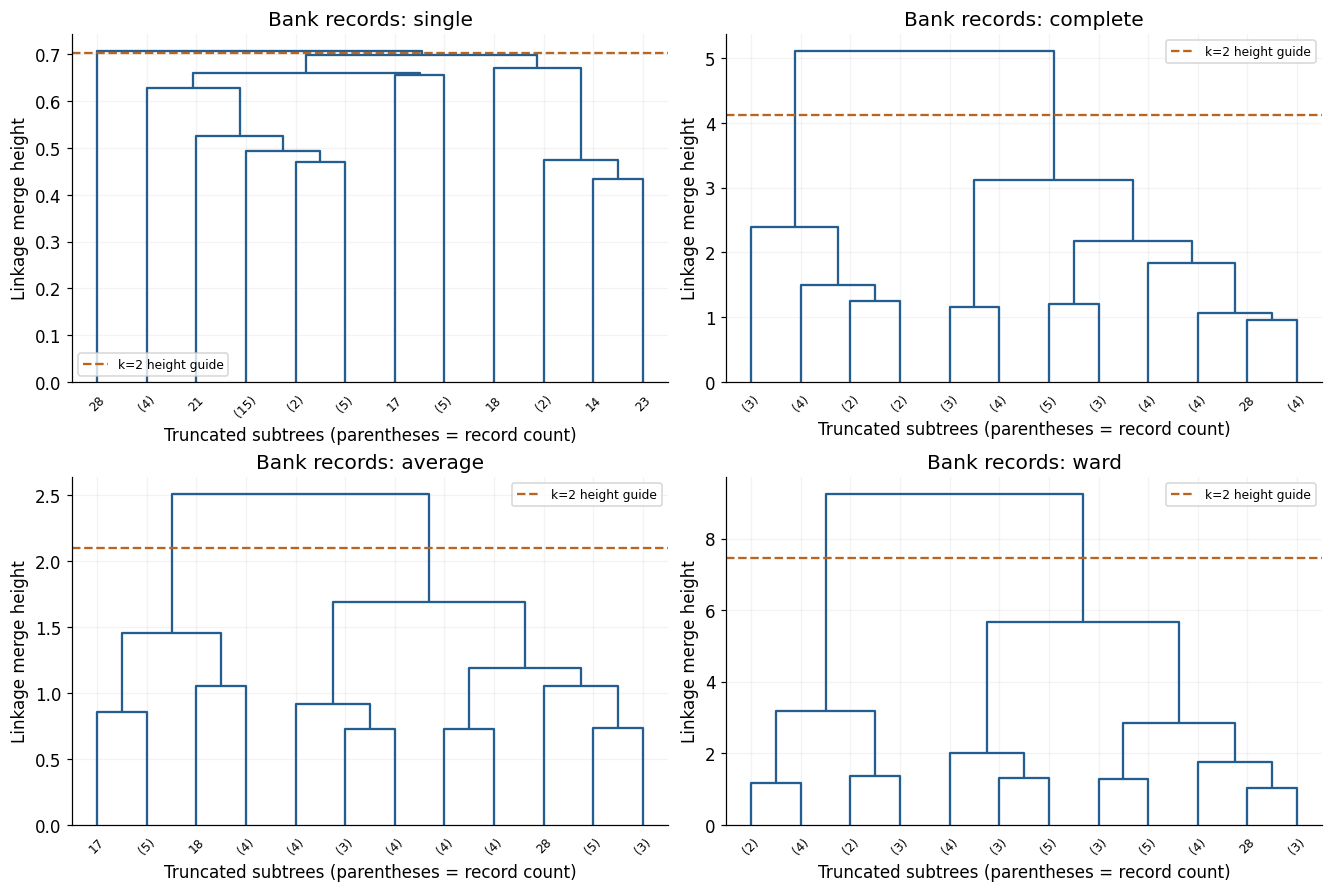

Read bottom to top: leaves/subtrees merge at the vertical-axis height. These are the last 12 subtrees, not 12 individual records. Single linkage joins by the nearest pair and can chain; complete uses the farthest pair; average uses mean pairwise distance. Ward minimizes the increase in within-cluster squared error and requires Euclidean geometry. Heights have linkage-specific meanings, so compare tree structure rather than raw heights across methods. Dashed guides illustrate the selected k; tied merge heights can make a height cut ambiguous, while the analysis uses an exact-k tree cut.

In [23]:
fig, axes = plt.subplots(2,2,figsize=(12,8),layout='constrained')
for ax, (method,tree) in zip(axes.ravel(),linkages.items()):
    dendrogram(tree, truncate_mode='lastp', p=12, show_leaf_counts=True,
        color_threshold=0, above_threshold_color='#245E91', ax=ax)
    # Same chosen k illustrates how merge heights differ, not a shared numeric threshold.
    lower, upper = tree[-chosen_k,2], tree[-chosen_k+1,2]
    height = (lower+upper)/2
    ax.axhline(height,color='#B96520',linestyle='--',label=f'k={chosen_k} height guide')
    ax.set(title=f'{plot_label}: {method}', xlabel='Truncated subtrees (parentheses = record count)',
           ylabel='Linkage merge height')
    ax.tick_params(axis='x',labelsize=8,rotation=45)
    ax.legend(fontsize=8)
plt.show()
display(Markdown('Read bottom to top: leaves/subtrees merge at the vertical-axis height. '
    'These are the last 12 subtrees, not 12 individual records. Single linkage joins by the nearest pair '
    'and can chain; complete uses the farthest pair; average uses mean pairwise distance. Ward minimizes '
    'the increase in within-cluster squared error and requires Euclidean geometry. Heights have linkage-specific '
    'meanings, so compare tree structure rather than raw heights across methods. Dashed guides illustrate '
    'the selected k; tied merge heights can make a height cut ambiguous, while the analysis uses an exact-k tree cut.'))

### C7. Compare algorithms on the same sample

,score population,silhouette,clusters,noise fraction,smallest cluster,largest share
method,,,,,,
K-means,all records,0.488,2,0.000,11,0.718
HAC average,all records,0.488,2,0.000,11,0.718
DBSCAN,assigned records only,0.462,5,0.385,3,0.231


HAC and k-means partition agreement: **ARI=1.000** on all 39 records. The same Euclidean silhouette favors compact groups and is also used for selection, so this is descriptive model exploration rather than an independent validation score.

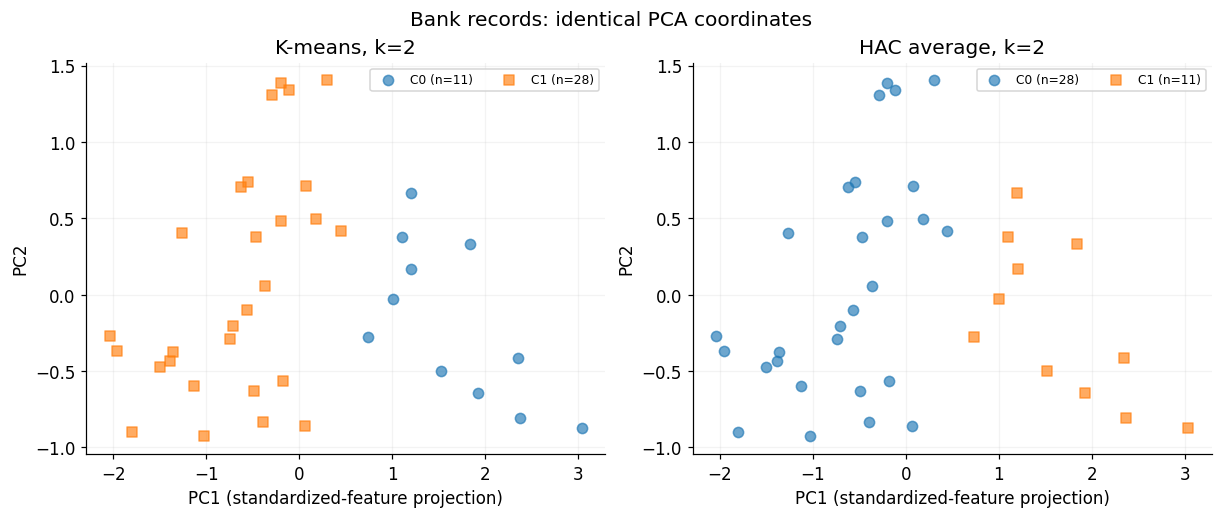

**Selected HAC profile.** Outcome fraction = checking account versus savings/CD; descriptive only.

,n,outcome fraction,median age_years,median tenure_years
cluster,,,,
0,28,0.464,37.802,14.137
1,11,0.273,66.007,42.894


**Interpretation:** HAC cluster sizes range from 11 to 28; outcome fractions range from 27.3% to 46.4%. These describe selected groups in the same sample, not causal effects, classifier accuracy or confirmed natural customer segments.

In [24]:
# Recompute Week 10's prespecified selection independently; no notebook-to-notebook hidden state.
km_rows, km_models = [], {}
for k in range(2,9):
    model = KMeans(n_clusters=k,n_init=20,random_state=SEED).fit(Z)
    km_models[k] = model
    km_rows.append({'k':k,'silhouette':safe_silhouette(Z,model.labels_), **cluster_stats(model.labels_)})
km_candidates = pd.DataFrame(km_rows).query('`smallest cluster` >= @min_cluster')
km_choice = km_candidates.sort_values(['silhouette','k'],ascending=[False,True]).iloc[0]
km_labels = km_models[int(km_choice['k'])].labels_
comparison_table = pd.DataFrame([
    {'method':'K-means','score population':'all records','silhouette':km_choice['silhouette'],**cluster_stats(km_labels)},
    {'method':f'HAC {chosen_method}','score population':'all records','silhouette':hac_choice['silhouette'],**cluster_stats(chosen_labels)},
    {'method':'DBSCAN' + ('' if db_supported else ' (illustrative)'), 'score population':'assigned records only',
        'silhouette':safe_silhouette(Z,db_labels),**cluster_stats(db_labels)}])
display(comparison_table.set_index('method'))
ari = adjusted_rand_score(km_labels,chosen_labels)
display(Markdown(f'HAC and k-means partition agreement: **ARI={ari:.3f}** on all {len(X):,} records. '
    'The same Euclidean silhouette favors compact groups and is also used for selection, so this is '
    'descriptive model exploration rather than an independent validation score.'))
fig, axes = plt.subplots(1,2,figsize=(11,4.6),layout='constrained')
scatter_clusters(coords,km_labels,axes[0],f'K-means, k={int(km_choice["k"])}')
scatter_clusters(coords,chosen_labels,axes[1],f'HAC {chosen_method}, k={chosen_k}')
fig.suptitle(f'{plot_label}: identical PCA coordinates')
plt.show()
hac_profile = profile(chosen_labels,'Selected HAC profile')
display(Markdown(f'**Interpretation:** HAC cluster sizes range from {hac_profile.n.min():,} '
    f'to {hac_profile.n.max():,}; outcome fractions range from {hac_profile["outcome fraction"].min():.1%} '
    f'to {hac_profile["outcome fraction"].max():.1%}. These describe selected groups in the same sample, '
    'not causal effects, classifier accuracy or confirmed natural customer segments.'))
results.append({'Dataset':plot_label,'n':len(X),'HAC linkage':chosen_method,'HAC k':chosen_k,
    'HAC silhouette':hac_choice['silhouette'],'K-means silhouette':km_choice['silhouette'],
    'HAC/K-means ARI':ari,'DBSCAN clusters':int(db_choice['clusters']),
    'DBSCAN noise':db_choice['noise fraction'],'DBSCAN meets rules':db_supported,
    'sample fingerprint':fingerprint})

## Takeaways across all three datasets

In [25]:
summary = pd.DataFrame(results).set_index('Dataset')
assert len(summary) == 3
display(summary)

,n,HAC linkage,HAC k,HAC silhouette,K-means silhouette,HAC/K-means ARI,DBSCAN clusters,DBSCAN noise,DBSCAN meets rules,sample fingerprint
Dataset,,,,,,,,,,
Loan Default,2000,ward,2,0.406,0.416,0.976,4,0.170,True,de56ac5c17ea8ad6
LendingClub,2000,ward,3,0.138,0.177,0.270,1,0.007,False,7fbf4b29f1965fd4
Bank records,39,average,2,0.488,0.488,1.000,5,0.385,True,58d445e664cb6d2b


## Milestone Two synthesis and limitations

Preserve the population, numeric feature definitions, scaling, selection rules, cluster-size distributions and any noise coverage when compiling Milestone Two. Cluster numbers are arbitrary labels, not risk ranks. Outcome profiles are exploratory associations on the selected data; they are neither held-out classifier accuracy nor causal evidence. Financial units differ across datasets, and log variables stay in log1p units in the profile tables.

Before treating these as useful segments, repeat the analysis on other samples and vintages, assess feature weighting/outlier handling, verify account/borrower identities, and test whether stable groups answer a concrete project question. Initialization stability alone does not establish sampling stability. DBSCAN density depends on sample size; eps from 2,000 rows should not be transferred unchanged to the full source. HAC has quadratic pairwise costs, so the bounded sample is intentional. The small bank cohort and repeated accounts prevent population conclusions.

The Milestone Two rubric was not provided. No course submission or Yellowdig posting has been performed.

## Yellowdig — draft initial post

**Source:** scikit-learn developers, [Clustering user guide — DBSCAN](https://scikit-learn.org/stable/modules/clustering.html#dbscan) (accessed November 22, 2026).

I consider this source high quality because it is maintained with the implementation and explains parameter behavior, noise and algorithm limitations. It helped me interpret eps and min_samples and recognize that a noise label is conditional on the chosen density settings. In my capstone I therefore report assigned coverage with the silhouette score and compare density results with hierarchical groups. This makes a highly separated but small assigned subset easier to recognize. The documentation explains the method; it does not establish that any resulting financial group is a true segment.

**Peer response prompt:** Investigate the posted source’s treatment of varying density or linkage, identify a specific strength, and explain how changing a parameter might alter the example. Actual peer posts are needed to write a respectful evidence-based reply.

## Sources and reproducibility

**Data:** the three original CSVs under `DATA/`, with the same source-loading/cohort logic as Week 9. Each dataset section prints counts, exclusions, missingness, feature ranges and a sampled-feature fingerprint. No web data supply the results.

**Methods:** the primary documentation linked in the method guide and Yellowdig section was consulted November 22, 2026. Versioned scikit-learn 1.8 API references match the pinned environment; stable example/guide and SciPy pages may describe newer versions. Installed versions are printed at setup. All method explanations are paraphrased, and all numerical findings are computed locally.

**Run:** from the repository, use `python3 -m jupyter nbconvert --execute --to notebook --inplace --ExecutePreprocessor.timeout=1200 "Week 11.ipynb"`. Install the existing pinned `requirements-notebooks.txt` into your environment if needed. The original CSVs are required. Every analytical output and the final results table recompute from the cells; the top summary describes the delivered saved run and should be revised if inputs/settings change.